In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Import dataset
df = pd.read_csv(
    "diabetic_data.csv",
    na_values=["?"],
    low_memory=False
)

# Display the dataset
print("\n The whole dataset")
print(df)





 The whole dataset
        encounter_id  patient_nbr             race  gender      age weight  \
0            2278392      8222157        Caucasian  Female   [0-10)    NaN   
1             149190     55629189        Caucasian  Female  [10-20)    NaN   
2              64410     86047875  AfricanAmerican  Female  [20-30)    NaN   
3             500364     82442376        Caucasian    Male  [30-40)    NaN   
4              16680     42519267        Caucasian    Male  [40-50)    NaN   
...              ...          ...              ...     ...      ...    ...   
101761     443847548    100162476  AfricanAmerican    Male  [70-80)    NaN   
101762     443847782     74694222  AfricanAmerican  Female  [80-90)    NaN   
101763     443854148     41088789        Caucasian    Male  [70-80)    NaN   
101764     443857166     31693671        Caucasian  Female  [80-90)    NaN   
101765     443867222    175429310        Caucasian    Male  [70-80)    NaN   

        admission_type_id  discharge_dispos

In [9]:
# Dataset information

print("\nDATASET INFORMATION")
print(df.info())




DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   encounter_id              101766 non-null  int64   
 1   patient_nbr               101766 non-null  int64   
 2   race                      99493 non-null   str     
 3   gender                    101766 non-null  str     
 4   age                       101766 non-null  category
 5   weight                    3197 non-null    str     
 6   admission_type_id         101766 non-null  int64   
 7   discharge_disposition_id  101766 non-null  int64   
 8   admission_source_id       101766 non-null  int64   
 9   time_in_hospital          101766 non-null  int64   
 10  payer_code                61510 non-null   str     
 11  medical_specialty         51817 non-null   str     
 12  num_lab_procedures        101766 non-null  int64   
 13  num_procedures     

In [ ]:
# Check dataset shape

print("\nDATASET SHAPE")
print(df.shape)

# Check column names

print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())




DATASET SHAPE
(101766, 50)

COLUMN NAMES
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

MISSING VALUES
encounter_id                    0
patient_nbr                     0
race                         2273
gender                

In [11]:
# Statistical summary

print("\nSTATISTICAL SUMMARY")
print(df.describe())

# Set age group order

age_order = [
    '[0-10)', '[10-20)', '[20-30)', '[30-40)',
    '[40-50)', '[50-60)', '[60-70)', '[70-80)',
    '[80-90)', '[90-100)'
]

df["age"] = pd.Categorical(
    df["age"],
    categories=age_order,
    ordered=True
)



STATISTICAL SUMMARY
       encounter_id   patient_nbr  admission_type_id  \
count  1.017660e+05  1.017660e+05      101766.000000   
mean   1.652016e+08  5.433040e+07           2.024006   
std    1.026403e+08  3.869636e+07           1.445403   
min    1.252200e+04  1.350000e+02           1.000000   
25%    8.496119e+07  2.341322e+07           1.000000   
50%    1.523890e+08  4.550514e+07           1.000000   
75%    2.302709e+08  8.754595e+07           3.000000   
max    4.438672e+08  1.895026e+08           8.000000   

       discharge_disposition_id  admission_source_id  time_in_hospital  \
count             101766.000000        101766.000000     101766.000000   
mean                   3.715642             5.754437          4.395987   
std                    5.280166             4.064081          2.985108   
min                    1.000000             1.000000          1.000000   
25%                    1.000000             1.000000          2.000000   
50%                    1.00000

age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64
Highest age group: [70-80)


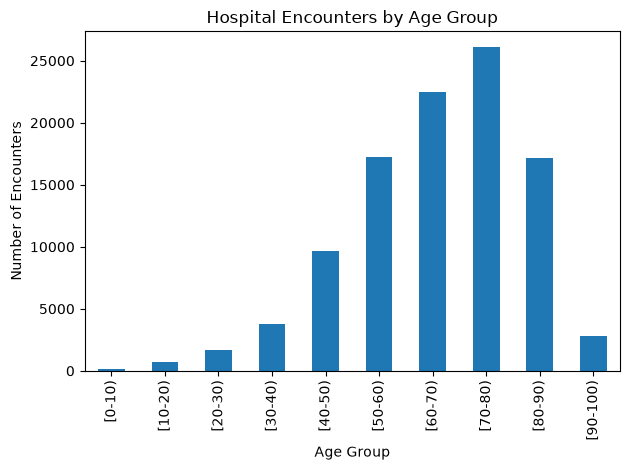

In [12]:
# Which age group has the highest number of hospital encounters?
age_counts = df["age"].value_counts(
    sort=False
)

age_counts = age_counts[age_counts > 0]

print(age_counts)

print(
    "Highest age group:",
    age_counts.idxmax()
)
age_counts.plot(
    kind="bar",
    title="Hospital Encounters by Age Group",
    xlabel="Age Group",
    ylabel="Number of Encounters"
)

plt.tight_layout()
plt.show()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


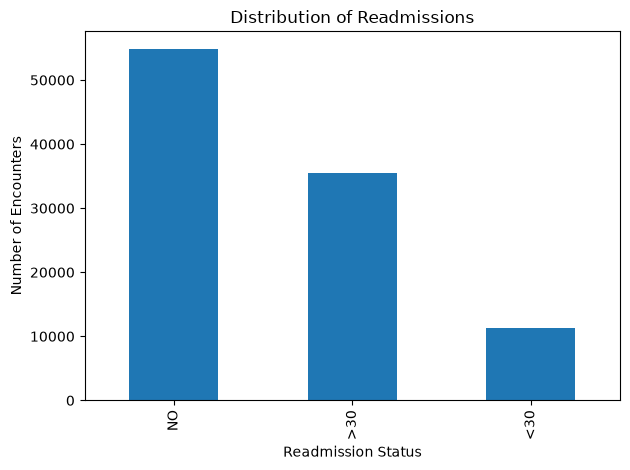

In [13]:
# What is the distribution of patient readmissions?

readmission_counts = df["readmitted"].value_counts()

readmission_order = ["NO", ">30", "<30"]

readmission_counts = readmission_counts.reindex(
    readmission_order
)

print(readmission_counts)
readmission_counts.plot(
    kind="bar",
    title="Distribution of Readmissions",
    xlabel="Readmission Status",
    ylabel="Number of Encounters"
)

plt.tight_layout()
plt.show()


age
[0-10)      18.01
[10-20)     38.21
[20-30)     45.02
[30-40)     42.68
[40-50)     44.45
[50-60)     43.96
[60-70)     46.25
[70-80)     48.12
[80-90)     48.27
[90-100)    40.03
Name: any_readmission, dtype: float64
Highest readmission percentage: [80-90)


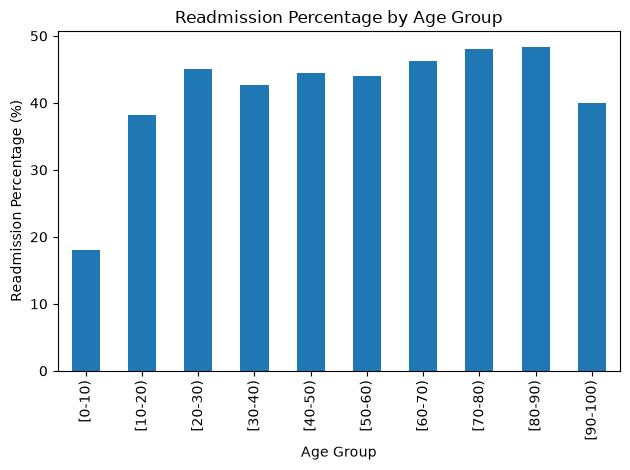

In [14]:
# Which age group has the highest readmission percentage?
df["any_readmission"] = df["readmitted"] != "NO"

readmission_by_age = (
    df.groupby("age", observed=False)["any_readmission"]
    .mean() * 100
).dropna()

print(readmission_by_age.round(2))

print(
    "Highest readmission percentage:",
    readmission_by_age.idxmax()
)

readmission_by_age.plot(
    kind="bar",
    title="Readmission Percentage by Age Group",
    xlabel="Age Group",
    ylabel="Readmission Percentage (%)"
)

plt.tight_layout()
plt.show()

readmitted
NO     4.25
>30    4.50
<30    4.77
Name: time_in_hospital, dtype: float64


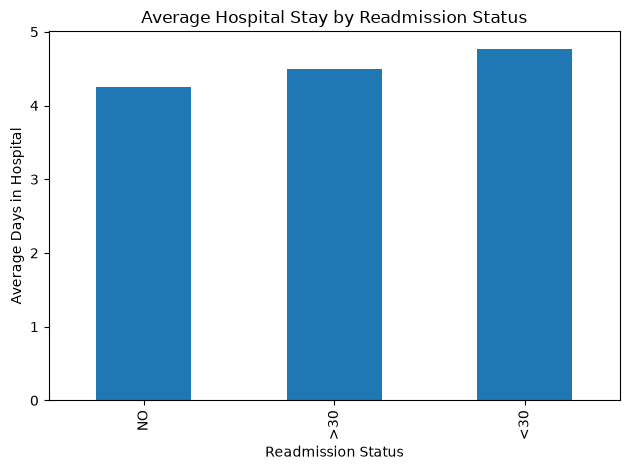

In [15]:
# What is the average hospital stay for each readmission category?
average_stay = (
    df.groupby("readmitted")["time_in_hospital"]
    .mean()
    .reindex(readmission_order)
)

print(average_stay.round(2))
average_stay.plot(
    kind="bar",
    title="Average Hospital Stay by Readmission Status",
    xlabel="Readmission Status",
    ylabel="Average Days in Hospital"
)

plt.tight_layout()
plt.show()

insulin                     54383
metformin                   19988
glipizide                   12686
glyburide                   10650
pioglitazone                 7328
rosiglitazone                6365
glimepiride                  5191
repaglinide                  1539
glyburide-metformin           706
nateglinide                   703
acarbose                      308
chlorpropamide                 86
tolazamide                     39
miglitol                       38
tolbutamide                    23
glipizide-metformin            13
troglitazone                    3
metformin-rosiglitazone         2
acetohexamide                   1
glimepiride-pioglitazone        1
metformin-pioglitazone          1
examide                         0
citoglipton                     0
dtype: int64
Most commonly recorded medication: insulin


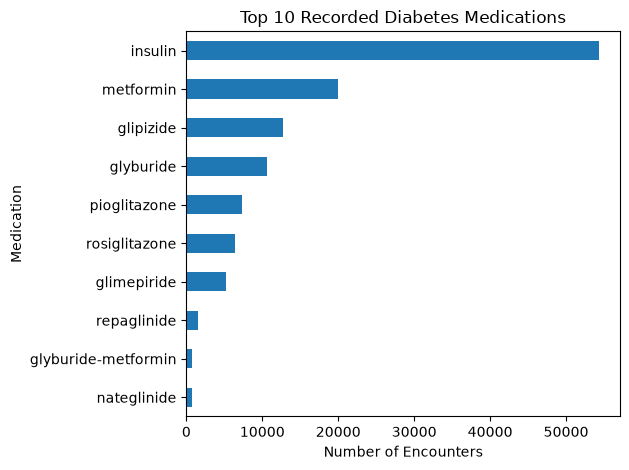

In [16]:
# QUESTION 5:
# Which diabetes medication is most commonly recorded as prescribed?

medication_columns = [
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "acetohexamide",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "examide",
    "citoglipton",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone"
]

medication_counts = (
    df[medication_columns]
    .isin(["Steady", "Up", "Down"])
    .sum()
    .sort_values(ascending=False)
)

print(medication_counts)

print(
    "Most commonly recorded medication:",
    medication_counts.idxmax()
)

medication_counts.head(10).sort_values().plot(
    kind="barh",
    title="Top 10 Recorded Diabetes Medications",
    xlabel="Number of Encounters",
    ylabel="Medication"
)

plt.tight_layout()
plt.show()


Readmission percentage by insulin status:
readmitted     NO    >30    <30
insulin                        
No          56.30  33.66  10.04
Down        47.21  38.89  13.90
Steady      54.89  33.98  11.13
Up          48.46  38.55  12.99


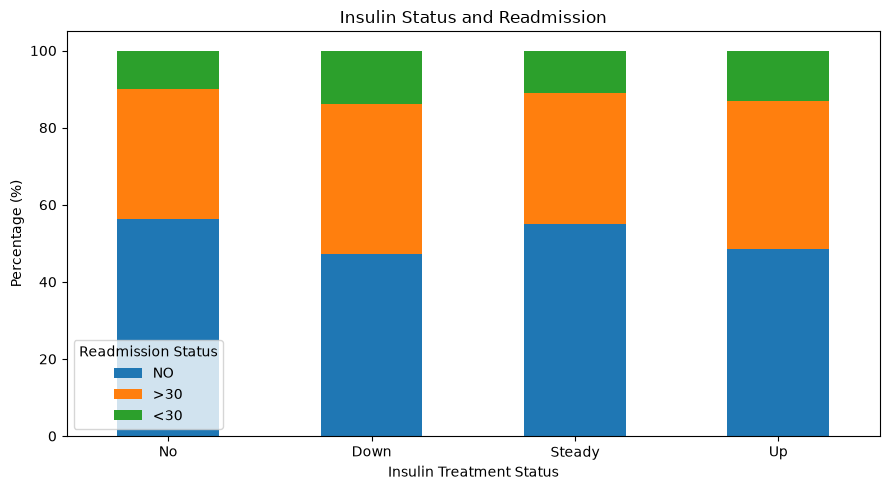

In [30]:
# How is insulin treatment status associated with readmission?
# # Calculate readmission percentages for each insulin treatment category

insulin_readmission = pd.crosstab(
    df["insulin"],
    df["readmitted"],
    normalize="index"
) * 100

# Arrange rows and columns in the correct order

insulin_readmission = insulin_readmission.reindex(
    index=["No", "Down", "Steady", "Up"],
    columns=readmission_order,
    fill_value=0
)

# Display results

print("\nReadmission percentage by insulin status:")
print(insulin_readmission.round(2))

# Create a stacked bar chart

ax = insulin_readmission.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    title="Insulin Status and Readmission",
    xlabel="Insulin Treatment Status",
    ylabel="Percentage (%)"
)

plt.legend(title="Readmission Status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


previous_inpatient_group
0 visits     38.49
1 visit      54.76
2 visits     64.94
3+ visits    74.69
Name: any_readmission, dtype: float64


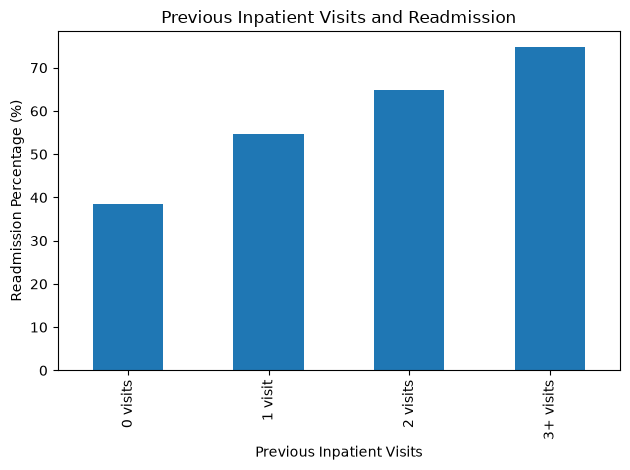

In [24]:
# Does the number of previous inpatient visits relate to readmission rates?

df["previous_inpatient_group"] = pd.cut(
    df["number_inpatient"],
    bins=[-1, 0, 1, 2, float("inf")],
    labels=["0 visits", "1 visit", "2 visits", "3+ visits"]
)

previous_readmission = (
    df.groupby(
        "previous_inpatient_group",
        observed=False
    )["any_readmission"]
     .mean() * 100
)

print(previous_readmission.round(2))

previous_readmission.plot(
    kind="bar",
    title="Previous Inpatient Visits and Readmission",
    xlabel="Previous Inpatient Visits",
    ylabel="Readmission Percentage (%)"
)

plt.tight_layout()
plt.show()


Average laboratory procedures by hospital stay:
time_in_hospital
1     32.92
2     37.70
3     40.39
4     43.80
5     46.75
6     48.50
7     50.12
8     51.42
9     53.27
10    53.57
11    54.26
12    54.89
13    55.60
14    55.59
Name: num_lab_procedures, dtype: float64


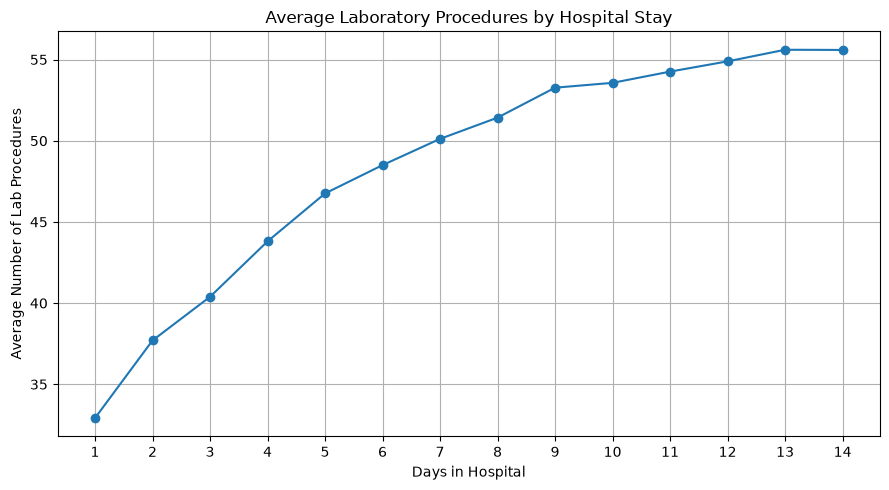

In [31]:
# How does the number of laboratory procedures vary with hospital stay duration?

# Calculate average laboratory procedures for each hospital stay duration

lab_by_stay = (
    df.groupby("time_in_hospital")["num_lab_procedures"]
    .mean()
    .sort_index()
)

# Display results

print("\nAverage laboratory procedures by hospital stay:")
print(lab_by_stay.round(2))

# Create a line chart

plt.figure(figsize=(9, 5))

plt.plot(
    lab_by_stay.index,
    lab_by_stay.values,
    marker="o"
)

plt.title("Average Laboratory Procedures by Hospital Stay")
plt.xlabel("Days in Hospital")
plt.ylabel("Average Number of Lab Procedures")

plt.xticks(range(1, 15))
plt.grid(True)

plt.tight_layout()
plt.show()


age
[0-10)       6.18
[10-20)      8.28
[20-30)     11.97
[30-40)     14.09
[40-50)     15.39
[50-60)     16.58
[60-70)     17.15
[70-80)     16.41
[80-90)     15.33
[90-100)    13.82
Name: num_medications, dtype: float64
Age group with highest average medications: [60-70)


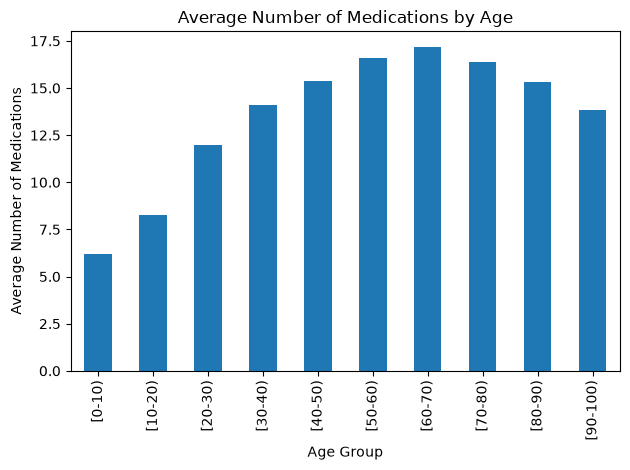

In [27]:
# Which age group receives the highest average number of medications?
medications_by_age = (
    df.groupby("age", observed=False)["num_medications"]
    .mean()
).dropna()

print(medications_by_age.round(2))

print(
    "Age group with highest average medications:",
    medications_by_age.idxmax()
    )

medications_by_age.plot(
    kind="bar",
    title="Average Number of Medications by Age",
    xlabel="Age Group",
    ylabel="Average Number of Medications"
)

plt.tight_layout()
plt.show()

                   Missing Values  Missing Percentage
weight                      98569               96.86
max_glu_serum               96420               94.75
A1Cresult                   84748               83.28
medical_specialty           49949               49.08
payer_code                  40256               39.56
race                         2273                2.23
diag_3                       1423                1.40
diag_2                        358                0.35
diag_1                         21                0.02


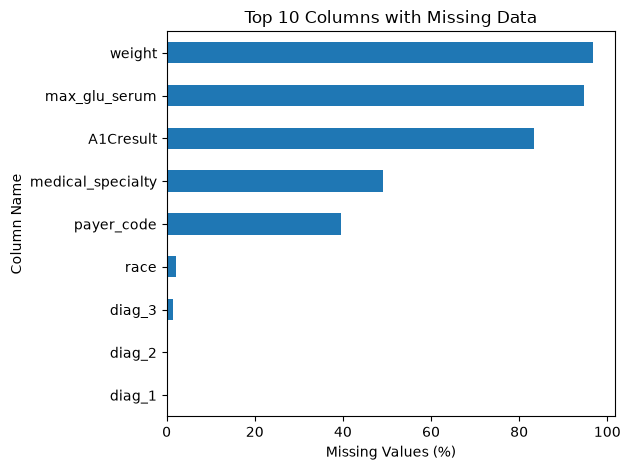

In [29]:
# Which columns have the most missing data?

missing_data = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_data = missing_data[
    missing_data["Missing Values"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)
print(missing_data.round(2))

missing_data.head(10)["Missing Percentage"].sort_values().plot(
    kind="barh",
    title="Top 10 Columns with Missing Data",
    xlabel="Missing Values (%)",
    ylabel="Column Name"
)

plt.tight_layout()
plt.show()